In [1]:
!pip install gym gym_bandits

In [2]:
import gym

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
import gym_bandits

In [4]:
import numpy as np

In [5]:
import matplotlib.pyplot as plt

In [6]:
np.bool8=np.bool_

In [7]:
base_env=gym.make("MultiarmedBandits-v0")

/usr/local/lib/python3.12/dist-packages/gym/core.py:317: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/usr/local/lib/python3.12/dist-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(


In [8]:
env=base_env.unwrapped

In [9]:
n_arms=env.action_space.n

In [10]:
episodes=500

In [11]:
print("no of arms",n_arms)

no of arms 10


In [12]:
epsilon=0.1

In [13]:
q_values=np.zeros(n_arms)

In [14]:
counts=np.zeros(n_arms)

In [15]:
rewards=[]

/tmp/ipykernel_2628/2116517328.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  q_values[action]+=(reward-q_values[action])/counts[action]



Epsilon-Greedy Results
Q-values: [ 0.09 -0.6   0.04  0.05 -0.13 -0.14 -0.02 -0.3  -0.43 -0.12]
Arm selection counts: [ 89   6 157 189  11  12  16  12   4   4]
Average reward: 0.023256671839674198


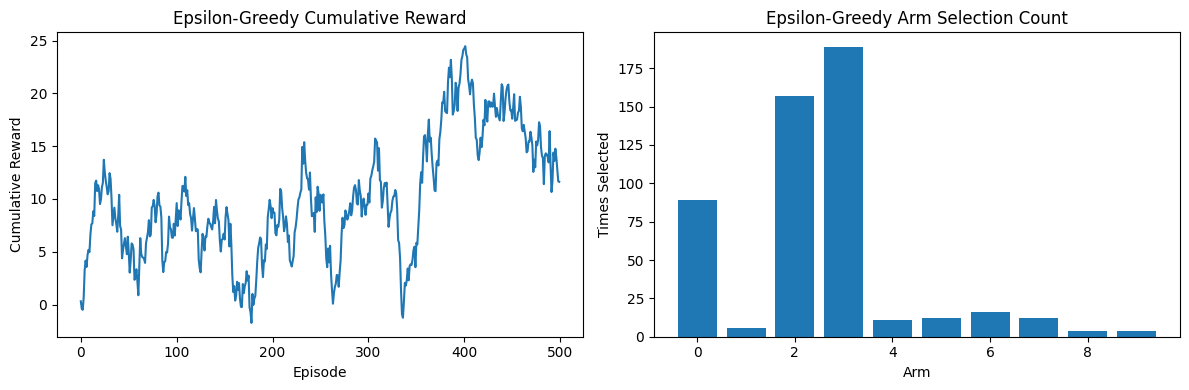


Softmax Results
Q-values: [-2.21 -0.09  0.09  0.05 -0.33 -2.3  -0.07  0.17  0.08 -1.74]
Arm selection counts: [  1  56  97  84  15   1  59 128  58   1]
Average reward: 0.039716411984569294


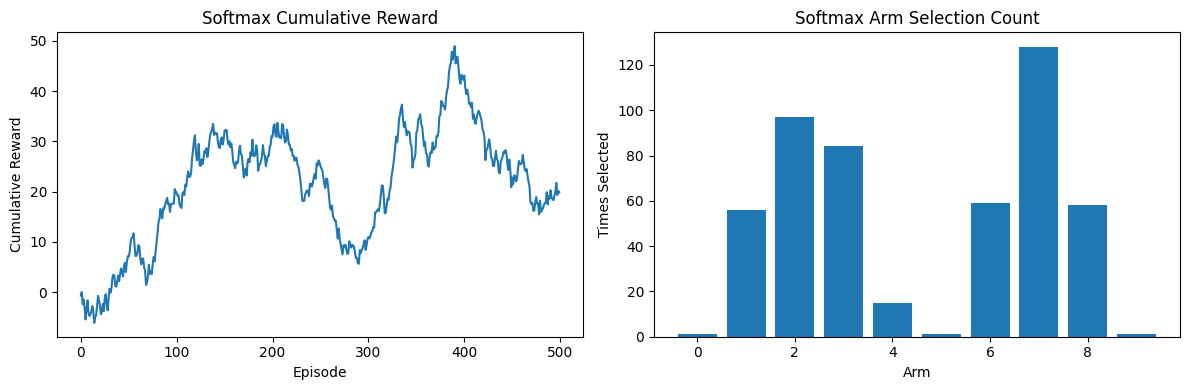

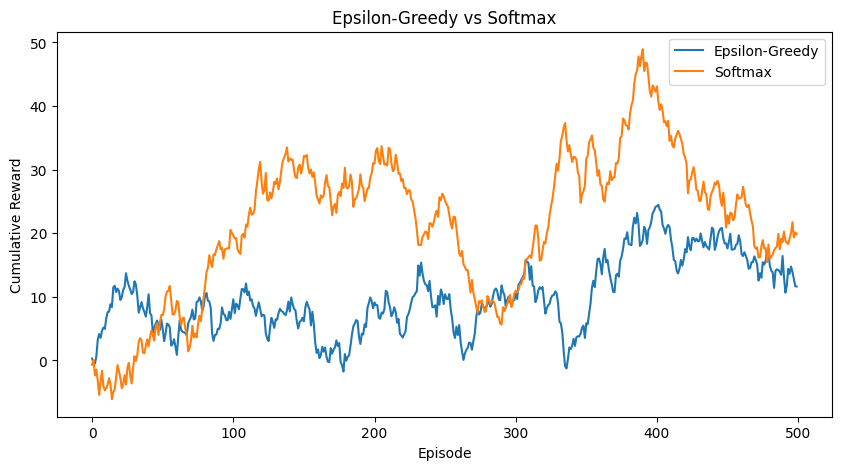

In [16]:
for episode in range(episodes):
  env.reset()
  if np.random.rand()<epsilon:\
    action=env.action_space.sample()
  else:
    action=np.argmax(q_values)
  observation,reward,done,info=env.step(action)
  counts[action]+=1
  q_values[action]+=(reward-q_values[action])/counts[action]
  rewards.append(reward)
print("\nEpsilon-Greedy Results")
print("Q-values:", np.round(q_values, 2))
print("Arm selection counts:", counts.astype(int))
print("Average reward:", np.mean(rewards))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards))
plt.title("Epsilon-Greedy Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts)
plt.title("Epsilon-Greedy Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
temperature = 0.5
q_values_softmax = np.zeros(n_arms)
counts_softmax = np.zeros(n_arms)
rewards_softmax = []
for episode in range(episodes):
    env.reset()
    probabilities = np.exp(q_values_softmax / temperature)
    probabilities = probabilities / np.sum(probabilities)
    action = np.random.choice(n_arms, p=probabilities)
    observation, reward, done, info = env.step(action)
    counts_softmax[action] += 1
    q_values_softmax[action] += (reward - q_values_softmax[action]) / counts_softmax[action]
    rewards_softmax.append(reward)
print("\nSoftmax Results")
print("Q-values:", np.round(q_values_softmax, 2))
print("Arm selection counts:", counts_softmax.astype(int))
print("Average reward:", np.mean(rewards_softmax))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(np.cumsum(rewards_softmax))
plt.title("Softmax Cumulative Reward")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.subplot(1, 2, 2)
plt.bar(range(n_arms), counts_softmax)
plt.title("Softmax Arm Selection Count")
plt.xlabel("Arm")
plt.ylabel("Times Selected")
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(
    np.cumsum(rewards),
    label="Epsilon-Greedy"
)
plt.plot(
    np.cumsum(rewards_softmax),
    label="Softmax"
)
plt.title("Epsilon-Greedy vs Softmax")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.legend()
plt.show()
env.close()
